# Endterm 03 - Feedforward ANN for EPA combined MPG

**Owner: Khamza.** Reproducible feedforward ANN experiment.

## Summary

The four-candidate CPU experiment selected **64 -> 32 hidden units, lr=0.001**.
The restored epoch-113 model obtained validation **MAE 1.083 MPG, RMSE 1.523 MPG,
R-squared 0.940** on 2,080 records. Training stopped at epoch 133.
These are validation-selected results, not an independent test estimate.
**No ANN test predictions or metrics are computed here.**

The notebook performs the full fixed-grid run from a clean kernel and overwrites
only its own endterm ANN artifacts. Use `project.ipynb` to present frozen results without rerunning training.

## Context and methods

**Question:** can a small feedforward ANN predict EPA combined **US MPG** from
the same vehicle specifications used by the midterm supervised models?
This remains regression on real FuelEconomy.gov data, not real-world driving
consumption. MAE (MPG) is primary; RMSE (MPG) and R-squared are secondary.

### Key assumptions

- Retain the existing local snapshot, filters and seed-42 grouped split.
- Fit imputers, input scalers, encoder and target scaler on **train only**.
- Reuse the inherited `displacement_per_cylinder` feature; no new feature search.
- Checkpoints use minimum validation MSE; the four configurations use validation
  MAE for final selection. This reuse introduces validation selection bias.
- The test partition is a **previously used midterm holdout**, not a new
  untouched endterm test. Membership hashes/counts are metadata only.
- Tabular data calls for a feedforward ANN; CNN/NLP/RL are not applicable.

Full contract: [endterm protocol](../../docs/endterm_protocol.md).

### 1. Setup

From the repository root, install the CPU environment described in
`README.md` / `requirements-endterm.txt`. Select that environment
as the kernel. The root is located from the current directory and its parents,
so running from `notebooks/endterm/` is supported. No internet download occurs.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists() and (p / 'src/vehicle_efficiency').exists())
from vehicle_efficiency.neural_network import (
    FIGURES_DIR, RESULTS_DIR, library_versions, load_ann, load_training_data,
    plot_learning_curves, run_experiment, verify_saved_run,
)
from vehicle_efficiency.preprocessing import split_xy

pd.set_option('display.precision', 4)
display(pd.Series(library_versions(), name='Tested version').to_frame())

,Tested version
python,3.12.3
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
torch,2.15.0+cpu
joblib,1.6.0
matplotlib,3.11.2
seaborn,0.13.2
jupyter,1.1.1


## Data

### 2. Verify the existing snapshot and split

Source: [EPA / DOE vehicles.csv](https://www.fueleconomy.gov/feg/epadata/vehicles.csv.zip),
[data dictionary](https://www.fueleconomy.gov/feg/ws/index.shtml).
Midterm documentation records acquisition on 2026-10-08, but that timestamp is
not independently established for the current local bytes. SHA-256 is the
authoritative local snapshot identity.

`load_training_data` verifies the committed manifest and returns **only train and
validation**, plus metadata. It recreates the inherited split to check row IDs;
it does not construct ANN inputs/targets or predictions for test.

In [3]:
train, val, manifest = load_training_data()
X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)
assert not {'mpg', 'comb08', 'row_id', 'make', 'model'} & set(X_train.columns)
assert set(train.row_id).isdisjoint(val.row_id)
display(pd.Series(manifest['split_sizes'], name='Records (membership only)').to_frame())
print('Raw SHA-256:', manifest['raw_sha256'])
print('Split assignment SHA-256:', manifest['split_assignments_sha256'])
print('Raw inputs:', ', '.join(manifest['raw_features']))
print('Engineered input: displacement_per_cylinder')
display(train[['mpg', 'cylinders', 'displacement']].describe().round(3))

,Records (membership only)
train,9816
val,2080
test,2079


Raw SHA-256: b1ff0e3071c46cdc1c99e0015878b98a01851462d7e447237ce2fc1294ccf303
Split assignment SHA-256: 3104489e6deddeb5cad770545d0fd8192bb432428a0039494705ef136eca01c7
Raw inputs: model_year, cylinders, displacement, hybrid, turbo, supercharged, drive, transmission, vehicle_class, fuel_type
Engineered input: displacement_per_cylinder


,mpg,cylinders,displacement
count,9816.000,9816.000,9816.000
mean,23.208,5.567,3.113
std,6.235,1.842,1.313
min,9.000,3.000,0.900
25%,19.000,4.000,2.000
50%,22.000,6.000,3.000
75%,26.000,6.000,3.600
max,59.000,16.000,8.400


## Experiment

### 3. Train the predeclared four candidates

Reusable implementation: `src/vehicle_efficiency/neural_network.py`.
Grid: hidden sizes `(32,)`, `(64,32)` crossed with learning rates `0.001`,
`0.0003`. All use seed 42, Adam, batch 64, maximum 200 epochs, patience 20.

ReLU provides nonlinearity with a simple gradient. The final linear unit predicts
a continuous standardised target without the range constraints of sigmoid or
softmax. MSE gives extra weight to larger errors; MAE in MPG remains the selection
and reporting metric. Input/target standardisation improves numerical conditioning.

All input and target transforms fit only on train. In each epoch only training
batches receive gradients. Full-split losses and MAEs are measured after updates.
The best weights are deep-copied and restored by validation MSE. Across restored
checkpoints, the lowest validation MAE wins. There is no hidden automatic split,
no test argument and no test-evaluation option.

In [4]:
model, history, search, metrics = run_experiment()
assert len(search) == 4 and search.selected.sum() == 1
assert not metrics['test_evaluated']
assert set(metrics) >= {'train', 'validation'} and 'test' not in metrics
print(model.network)
print('Transformed input dimensions:', model.network[0].in_features)
print('Target mean/std (train only):', model.target_scaler.mean_[0], model.target_scaler.scale_[0])

Sequential(
  (0): Linear(in_features=40, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Transformed input dimensions: 40
Target mean/std (train only): 23.207518337408313 6.234224468331758


## Results

### 4. Search results at restored checkpoints

Metrics below use unrounded, inverse-transformed predictions. Epoch counts include
the patience period; best epoch identifies the stored checkpoint. No CV score is
claimed for the ANN. The completed endterm comparison uses the same validation rows while
acknowledging the different tuning procedures.

In [5]:
columns = ['candidate', 'best_epoch', 'epochs_run', 'stopped_early',
           'train_mae', 'val_mae', 'val_rmse', 'val_r2', 'selected']
display(search[columns].round(4))
display(pd.DataFrame({'Train': metrics['train'],
                      'Validation': metrics['validation']}).T.rename(
    columns={'mae': 'MAE (MPG)', 'rmse': 'RMSE (MPG)', 'r2': 'R-squared'}).round(4))
chosen = history[history.selected]
best_row = chosen.loc[chosen.is_best_epoch].iloc[0]
last_row = chosen.iloc[-1]
display(Markdown(
    f"**Selected:** `{metrics['selected_candidate']}`. Best epoch **{model.best_epoch}**; "
    f"training ended at **{int(last_row.epoch)}**. "
    f"Train/validation MAE gap: **{metrics['validation']['mae'] - metrics['train']['mae']:.3f} MPG**."
))

,candidate,best_epoch,epochs_run,stopped_early,train_mae,val_mae,val_rmse,val_r2,selected
0,h64-32_lr0.001,113,133,True,0.9460,1.0827,1.5230,0.9396,True
1,h64-32_lr0.0003,195,200,False,0.9723,1.1090,1.5580,0.9368,False
2,h32_lr0.001,95,115,True,1.1345,1.2067,1.6567,0.9285,False
3,h32_lr0.0003,200,200,False,1.1591,1.2409,1.6906,0.9256,False


,MAE (MPG),RMSE (MPG),R-squared
Train,0.9460,1.3111,0.9558
Validation,1.0827,1.5230,0.9396


**Selected:** `h64-32_lr0.001`. Best epoch **113**; training ended at **133**. Train/validation MAE gap: **0.137 MPG**.

### 5. Learning curves and configuration comparison

The plotting function below is reusable/editable Python code in the ANN module.
Loss is MSE of the training-standardised target; the right panel reports MPG.
The vertical marker identifies the restored epoch, not the epoch with minimum MAE.

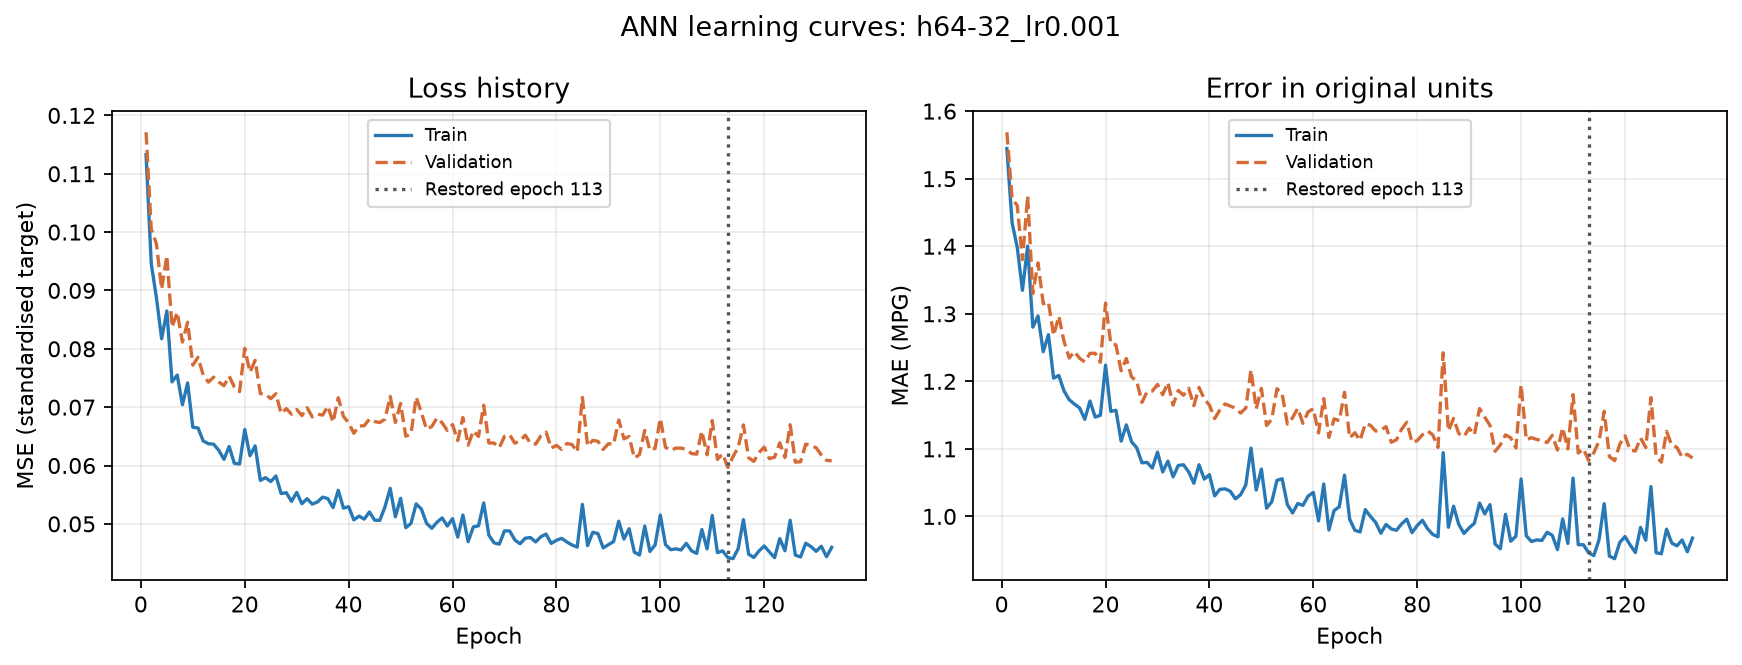

In [6]:
plot_learning_curves(history, search)
display(Image(filename=str(FIGURES_DIR / 'ann_learning_curves.png')))

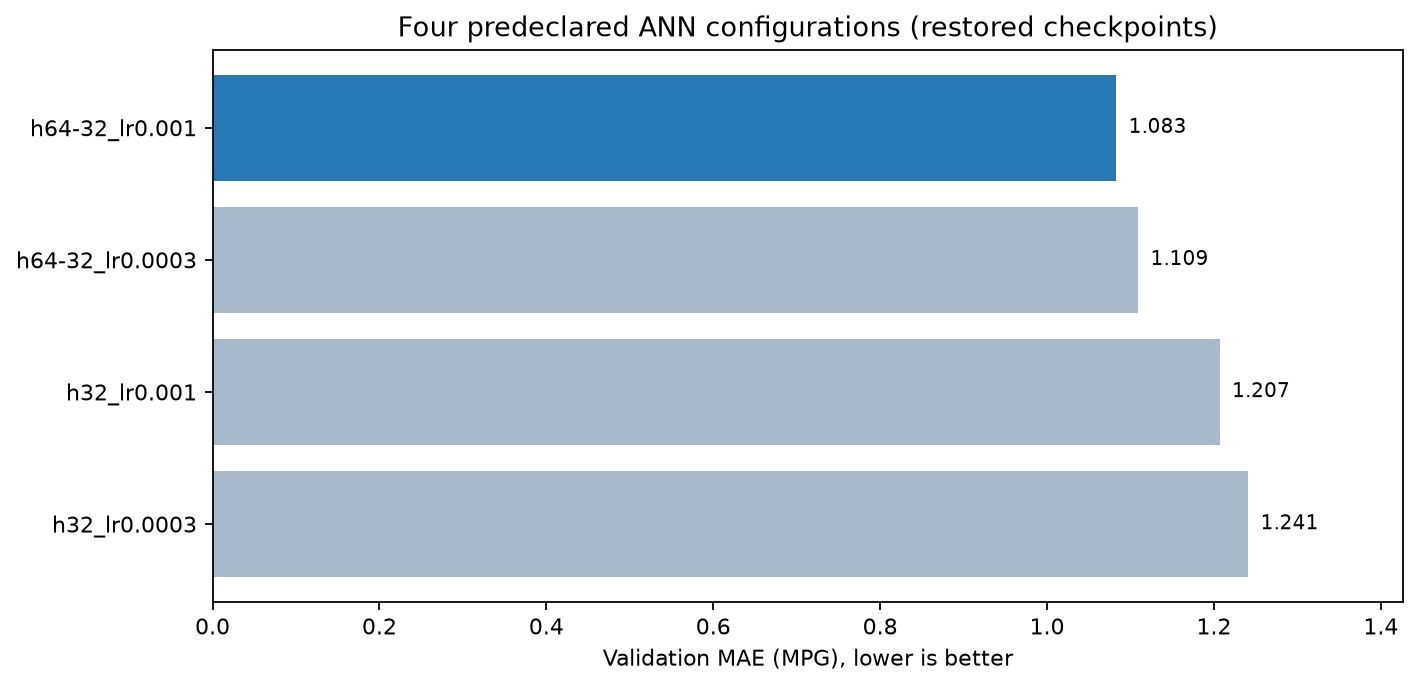

Validation loss fell from **0.1171** after epoch 1 to **0.0597** at the restored checkpoint. At the final trained epoch it was **0.0608**. Restoring changes the final-epoch validation MAE from **1.0865** to **1.0827 MPG**. This is a within-run checkpoint comparison, not an ablation proving an early-stopping benefit.

In [7]:
display(Image(filename=str(FIGURES_DIR / 'ann_search_validation.png')))
display(Markdown(
    f"Validation loss fell from **{chosen.iloc[0].val_loss:.4f}** after epoch 1 "
    f"to **{best_row.val_loss:.4f}** at the restored checkpoint. "
    f"At the final trained epoch it was **{last_row.val_loss:.4f}**. "
    f"Restoring changes the final-epoch validation MAE from **{last_row.val_mae:.4f}** "
    f"to **{metrics['validation']['mae']:.4f} MPG**. "
    "This is a within-run checkpoint comparison, not an ablation proving an early-stopping benefit."
))

**Interpretation.** Loss decreases substantially and then fluctuates around a
plateau. The 0.137 MPG train/validation gap indicates some fitting to training-specific
patterns; it is not evidence of catastrophic overfitting. The deeper architecture
has lower validation MAE at both declared learning rates. The smaller learning
rate hits the 200-epoch budget in both architectures, so a larger budget could
change the ranking; that was not tried after seeing these results.

The selected model stops at 133 and restores 113. Early stopping avoids keeping
the final slightly worse-loss checkpoint and saves 67 epochs relative to the
200-epoch cap. We did not run a no-early-stopping experiment, so there is no claim
about its causal effect on generalisation. No uncertainty intervals or
statistical significance claims are available from this single-seed experiment.

### 6. Final endterm supervised comparison

The table below reads the completed six-model endterm comparison on the verified shared snapshot and validation rows. Classical models use training-only grouped CV; the ANN uses validation for checkpoints and configuration selection. MAE is primary. Holdout scores are reported separately in `04_evaluation.ipynb` and were not used to select another model.

In [8]:
comparison = pd.read_csv(RESULTS_DIR / 'model_comparison_validation.csv')
ann_row = comparison.set_index('model').loc['Feedforward ANN']
for metric in ('mae', 'rmse', 'r2'):
    np.testing.assert_allclose(ann_row[f'validation_{metric}'],
                               metrics['validation'][metric], rtol=0, atol=1e-4)
display(comparison[['model', 'validation_mae', 'validation_rmse',
                    'validation_r2']].round(4))

,model,validation_mae,validation_rmse,validation_r2
0,Decision Tree,1.0510,1.6365,0.9303
1,Feedforward ANN,1.0827,1.5230,0.9396
2,KNN,1.0894,1.6722,0.9272
3,Linear Regression,2.0186,2.7779,0.7990
4,Ridge,2.0205,2.7784,0.7990
5,Baseline (mean),4.6618,6.1967,-0.0000


ANN validation MAE 1.083 is slightly higher than the endterm Decision Tree MAE 1.051; ANN RMSE 1.523 is lower than the tree's 1.636. **MAE is primary**, so the tree remains the selected model. A small neural network is not guaranteed to beat a tree on structured vehicle specifications. Related vehicle variants may favor local tree/KNN predictions; this is a possible explanation, not an established causal finding.

### 7. Validate persistence and row-level integration

The stored bundle contains weights, the fitted input pipeline and the fitted
target scaler. `load_ann(...).predict(X)` performs inference without training.
The checksum guards against mixing bundle files. Only load trusted joblib files.

In [9]:
loaded = load_ann(expected_manifest=manifest)
np.testing.assert_array_equal(model.predict(X_val), loaded.predict(X_val))
validation_predictions = pd.read_csv(RESULTS_DIR / 'ann_predictions_validation.csv')
assert len(validation_predictions) == len(val)
assert validation_predictions.row_id.is_unique
assert np.isfinite(validation_predictions.y_pred).all()
display(validation_predictions.head())
display(verify_saved_run())

,row_id,y_true,y_pred
0,27061,32,28.7373
1,27067,28,26.1818
2,27069,27,25.0294
3,27073,26,23.2589
4,27074,20,19.1235


{'snapshot_and_split': 'match',
 'validation_rows': 2080,
 'predictions_and_metrics': 'match',
 'test_evaluated': False}

## Conclusions

- The four-candidate CPU experiment selected 40 -> 64 -> 32 -> 1, ReLU, Adam lr 0.001, batch 64. Early stopping restored epoch 113 after stopping at 133.
- Validation MAE is 1.083 MPG. Validation selected both checkpoints and configuration, so it is not an independent evaluation.
- The final endterm comparison retains Decision Tree as the primary-MAE winner; ANN has lower validation RMSE.
- This training notebook does not evaluate test. The separate completed evaluation reports ANN holdout MAE 1.078 MPG; that holdout was already used in midterm and is not a fresh independent test.
- Missing weight, horsepower, hybrid-system detail and driving conditions limit predictions. Related make/model variants can cross splits. EPA ratings are not real-world fuel-use guarantees.
- Fixed seeds support repeatability in the recorded environment, not bitwise equality across every OS/CPU/library combination.

For defense, use `project.ipynb`; for error analysis and recorded holdout metrics, use `04_evaluation.ipynb`. Implementation: `src/vehicle_efficiency/neural_network.py`. `python -m vehicle_efficiency.neural_network --verify` checks the saved bundle without retraining or predicting test.

Running this notebook retrains the same declared grid and refreshes ANN artifacts. Implementation references: [PyTorch reproducibility](https://docs.pytorch.org/docs/2.15/notes/randomness.html), [saving/loading state_dict](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).